# Reading a catalog download (`<job ID>.zip`)

A catalog download holds these files for each snapshot you requested:

| File | What it holds | Section |
|---|---|---|
| `galaxy_NNNN.pkl` or `.txt` (`halo_NNNN` for halos) | One row per object, properties as columns | 2–8 |
| `galaxy_pid_NNNN.pkl` or `.txt` | Member particle IDs of each object (only if requested) | 4-(2) |
| `snapinf_NNNN.txt` | Snapshot metadata (`aexp`, aperture lists) | 9 |
| `error.txt` | Requested snapshots that could not be produced (only if any) | 9-(5) |

This notebook needs Python 3.7+, NumPy and `ndps_reader.py`, which sits one folder up. Sections 7 and 8 also use matplotlib and pandas.

The outputs shown come from a NewCluster galaxy download of snapshots 700–750. Halo downloads work the same way, with `halo_` in place of `galaxy_`.

In [ ]:
import sys
sys.path.insert(0, '..')   # ndps_reader.py is one folder up; not needed if you pip-installed it

from pathlib import Path
import zipfile
import numpy as np
import ndps_reader as nr

print('ndps_reader', nr.__version__)

ndps_reader 0.1.0


## 1. Unzip the download

Set `ZIP_FILE` to your download. The first run extracts it into a folder of the same name.

In [ ]:
ZIP_FILE = Path('20261103_288872.zip')   # <- your download

def extract(zip_file):
    """Unzip a download once, into a folder named after it."""
    folder = zip_file.with_suffix('')
    if not folder.exists():
        with zipfile.ZipFile(zip_file) as archive:
            archive.extractall(folder)
    return folder

DATA_DIR = extract(ZIP_FILE)
files = sorted(p.name for p in DATA_DIR.iterdir())
print(len(files), 'files:', files[:4], '...', files[-2:])

53 files: ['error.txt', 'galaxy_0700.pkl', 'galaxy_0702.pkl', 'galaxy_0704.pkl'] ... ['snapinf_0748.txt', 'snapinf_0750.txt']


## 2. Read one snapshot

`read_catalog` takes a `.pkl` or `.txt` path and returns a NumPy **structured array**: one row per galaxy and one named field per property.

### 2-(1) Read one snapshot (pickle)

In [ ]:
SNAP = 700
cat = nr.read_catalog(DATA_DIR / f'galaxy_{SNAP:04d}.pkl')

print(type(cat).__name__, cat.shape)
print(len(cat.dtype.names), 'properties')

ndarray (3614,)
60 properties


Every property, with its type, and either `scalar` (one number per galaxy) or the length of the vector:

In [ ]:
for name in cat.dtype.names:
    shape = cat.dtype[name].shape
    print(f'{name:20s} {str(cat.dtype[name].base):8s} {shape if shape else "scalar"}')

ABmag_NUV            float64  (3,)
ABmag_g              float64  (3,)
ABmag_i              float64  (3,)
ABmag_r              float64  (3,)
ABmag_u              float64  (3,)
ABmag_z              float64  (3,)
ConFrac_M            float64  (2,)
ConFrac_N            float64  (2,)
Efrac                float64  scalar
GasMass_bound_cold   float64  (3,)
GasMass_bound_hot    float64  (3,)
GasMass_bound_tot    float64  (3,)
GasMass_cgm_cold     float64  (3,)
GasMass_cgm_hot      float64  (3,)
GasMass_cgm_tot      float64  (3,)
GasMass_icm_cold     float64  (3,)
GasMass_icm_hot      float64  (3,)
GasMass_icm_tot      float64  (3,)
GasMass_tot_cold     float64  (3,)
GasMass_tot_hot      float64  (3,)
GasMass_tot_tot      float64  (3,)
GravPressure         float64  scalar
ID                   int64    scalar
ID_mbp               int64    scalar
Lx                   float64  scalar
Ly                   float64  scalar
Lz                   float64  scalar
Mass_200crit         float64  scalar
Mass

### 2-(2) Read one snapshot (ASCII)

An ASCII download is read with the same call:

In [ ]:
TXT_ZIP = Path('20261103_821953.zip')   # <- an ASCII download of the same snapshots, or None to skip

if TXT_ZIP is not None:
    txt = nr.read_catalog(extract(TXT_ZIP) / f'galaxy_{SNAP:04d}.txt')
    print(txt.shape, len(txt.dtype.names), 'properties')

(3614,) 60 properties


The file is a tab-separated table. Its first line names the columns, and a vector is spread over `SFR[0]`, `SFR[1]`, … columns. `read_catalog` joins those back into one field.

In [ ]:
if TXT_ZIP is not None:
    with open(extract(TXT_ZIP) / f'galaxy_{SNAP:04d}.txt') as f:
        header = f.readline().rstrip('\n').split('\t')
    print(len(header), 'columns:', header[:4], '...', header[-2:])

124 columns: ['# ABmag_NUV[0]', 'ABmag_NUV[1]', 'ABmag_NUV[2]', 'ABmag_g[0]'] ... ['numSubStruct', 'sigV']


The values are the same as in the pickle. Only some dtypes differ, because ASCII stores no types: columns of whole numbers come back as int64 and all others as float64.

In [ ]:
if TXT_ZIP is not None:
    same = all(np.array_equal(cat[n], txt[n], equal_nan=True) for n in cat.dtype.names)
    print('same values as the pickle:', same)
    for n in cat.dtype.names:
        if cat.dtype[n].base != txt.dtype[n].base:
            print(f'  {n}: pkl {cat.dtype[n].base}, txt {txt.dtype[n].base}')

same values as the pickle: True
  Structuretype: pkl int32, txt int64
  npart: pkl int32, txt int64
  numSubStruct: pkl int32, txt int64


## 3. Scalar properties

Indexing with a field name gives a 1-D array, one value per galaxy. Indexing with an integer gives one galaxy, which you can then index by field name.

In [ ]:
mass = cat['Mass_tot']
print(mass.shape, mass[:3])

g = cat[0]
print('ID', g['ID'], '  Mass_tot', g['Mass_tot'], '  position', (g['Xc'], g['Yc'], g['Zc']))

(3614,) [1.14249236e+12 3.28740991e+11 3.44350622e+11]
ID 1   Mass_tot 1142492355000.0   position (43088.35798, 41944.26416, 42599.39207)


Pass a list of names to take several fields at once:

In [ ]:
for row in cat[['ID', 'Mass_tot', 'R_HalfMass']][:3]:
    print(row)

(1, 1.14249236e+12, 5.13109271)
(2, 3.28740991e+11, 4.06795186)
(3, 3.44350622e+11, 5.90309741)


## 4. Vector properties

Some properties hold several values per galaxy: the aperture vectors in the catalog, and the member particle IDs in `galaxy_pid_NNNN`.

### 4-(1) Catalog vectors

`SFR`, for example, has 15. Index the second axis to pick one of them:

In [ ]:
print(cat['SFR'].shape)      # (galaxies, 15)
print(cat['SFR'][:3, 0])     # first SFR value of the first three galaxies

(3614, 15)
[ 2.8561693 32.0398018 13.3770523]


`snapinf_NNNN.txt` says what each position stands for (see section 9):

| Property | Length | List in `snapinf_NNNN.txt` |
|---|---|---|
| `ABmag_<band>` | 3 | `MAG_R` |
| `GasMass_<region>_<phase>` | 3 | `GAS_R` |
| `ConFrac_M`, `ConFrac_N` | 2 | `CONF_R` |
| `SFR` | 15 | `SFR_R` and `SFR_T`, one pair per position |

The bands are listed in `Flux_List`. `GRAV_R` has a single value, so `GravPressure` is stored as a scalar.

In [ ]:
info = nr.read_snapinfo(DATA_DIR / f'snapinf_{SNAP:04d}.txt')
print('Flux_List:', info['Flux_List'])
print('MAG_R    :', info['MAG_R'])
print()
for k, r in enumerate(info['MAG_R']):
    print(f"ABmag_r[:, {k}]  MAG_R = {r:>4}   first galaxy: {cat['ABmag_r'][0, k]:.3f}")

Flux_List: ['NUV', 'u', 'g', 'r', 'i', 'z']
MAG_R    : [-1.0, 0.1, 1.0]

ABmag_r[:, 0]  MAG_R = -1.0   first galaxy: -25.078
ABmag_r[:, 1]  MAG_R =  0.1   first galaxy: -21.069
ABmag_r[:, 2]  MAG_R =  1.0   first galaxy: -24.281


In [ ]:
for k, (r, t) in enumerate(zip(info['SFR_R'], info['SFR_T'])):
    print(f'SFR[:, {k:2d}]  SFR_R = {r:>4}  SFR_T = {t}')

SFR[:,  0]  SFR_R = -1.0  SFR_T = 0.01
SFR[:,  1]  SFR_R =  0.1  SFR_T = 0.01
SFR[:,  2]  SFR_R =  1.0  SFR_T = 0.01
SFR[:,  3]  SFR_R = -1.0  SFR_T = 0.05
SFR[:,  4]  SFR_R =  0.1  SFR_T = 0.05
SFR[:,  5]  SFR_R =  1.0  SFR_T = 0.05
SFR[:,  6]  SFR_R = -1.0  SFR_T = 0.1
SFR[:,  7]  SFR_R =  0.1  SFR_T = 0.1
SFR[:,  8]  SFR_R =  1.0  SFR_T = 0.1
SFR[:,  9]  SFR_R = -1.0  SFR_T = 0.5
SFR[:, 10]  SFR_R =  0.1  SFR_T = 0.5
SFR[:, 11]  SFR_R =  1.0  SFR_T = 0.5
SFR[:, 12]  SFR_R = -1.0  SFR_T = 1.0
SFR[:, 13]  SFR_R =  0.1  SFR_T = 1.0
SFR[:, 14]  SFR_R =  1.0  SFR_T = 1.0


A helper that picks the `SFR` column by its `SFR_R` and `SFR_T` values instead of by position:

In [ ]:
def sfr(cat, info, r, t):
    """SFR of every galaxy for SFR_R = r and SFR_T = t."""
    pairs = list(zip(info['SFR_R'], info['SFR_T']))
    return cat['SFR'][:, pairs.index((r, t))]

sfr(cat, info, r=1.0, t=0.1)[:5]

array([ 2.58563091, 15.93618118,  3.09440751,  1.01504489, 15.08370199])

### 4-(2) Member particle IDs (`galaxy_pid_NNNN`)

If you request member particles, the download also has a `galaxy_pid_NNNN` file for each snapshot. `read_members` reads the `.pkl` or `.txt` version:

In [ ]:
PID_ZIP = Path('20261103_000000.zip')   # <- a download made with member particles, or None to skip

if PID_ZIP is not None:
    PID_DIR = extract(PID_ZIP)
    pid = nr.read_members(PID_DIR / f'galaxy_pid_{SNAP:04d}.pkl')
    print(pid.shape, pid.dtype.names)

There is one row per galaxy, with three fields:

| Field | Contents |
|---|---|
| `ID` | Galaxy ID, the same as `ID` in `galaxy_NNNN` |
| `Npart` | Number of member particles |
| `P_ID` | Array of the member particle IDs, `Npart` long |

Each galaxy has a different number of particles, so each `P_ID` entry is a separate NumPy array.

In [ ]:
if PID_ZIP is not None:
    first = pid[0]
    print('ID', first['ID'], '  Npart', first['Npart'])
    print('first particle IDs:', first['P_ID'][:10])

To get the particles of a galaxy, match rows by `ID` rather than by position:

In [ ]:
if PID_ZIP is not None:
    pcat = nr.read_catalog(PID_DIR / f'galaxy_{SNAP:04d}.pkl')
    pid_of = {id_: p for id_, p in zip(pid['ID'], pid['P_ID'])}

    g = pcat[np.argmax(pcat['Mass_tot'])]
    particles = pid_of[g['ID']]
    print(f"most massive galaxy, ID {g['ID']}: {len(particles)} particles (catalog npart = {g['npart']})")

    massive_ids = pcat['ID'][pcat['Mass_tot'] > 1e11]
    massive_particles = np.concatenate([pid_of[i] for i in massive_ids])
    print(len(massive_ids), 'galaxies with Mass_tot > 1e11,', len(massive_particles), 'particles')

## 5. Select, sort and look up galaxies

A comparison gives a True/False mask, and indexing with the mask keeps the matching rows. When combining conditions with `&` (and) or `|` (or), put each condition in parentheses.

In [ ]:
massive = cat[cat['Mass_tot'] > 1e11]
print(len(massive), 'galaxies with Mass_tot > 1e11')

compact = cat[(cat['Mass_tot'] > 1e10) & (cat['R_HalfMass'] < np.median(cat['R_HalfMass']))]
print(len(compact), 'galaxies with Mass_tot > 1e10 and a below-median R_HalfMass')

17 galaxies with Mass_tot > 1e11
28 galaxies with Mass_tot > 1e10 and a below-median R_HalfMass


In [ ]:
order = np.argsort(cat['Mass_tot'])[::-1]    # most massive first
top = cat[order[:5]]
for g in top:
    print(f"ID {g['ID']:5d}  Mass_tot {g['Mass_tot']:.3e}  npart {g['npart']}")

ID     1  Mass_tot 1.142e+12  npart 64367508
ID  2040  Mass_tot 7.416e+11  npart 40998821
ID  2039  Mass_tot 4.413e+11  npart 24592075
ID     3  Mass_tot 3.444e+11  npart 19513677
ID     2  Mass_tot 3.287e+11  npart 18824482


To find a galaxy by its `ID`:

In [ ]:
target = top[0]['ID']
g = cat[cat['ID'] == target][0]
print(g['ID'], g['Mass_tot'])

# For many lookups, build a dict from ID to row once
row_of = {id_: i for i, id_ in enumerate(cat['ID'])}
cat[row_of[target]]['Mass_tot']

1 1142492355000.0


1142492355000.0

IDs are numbered within each snapshot (here 1 to N). The same ID in another snapshot does not mean the same galaxy.

## 6. Several snapshots

Loop over the catalog files in the folder. The pattern `galaxy_[0-9]*` leaves out the `galaxy_pid_` files.

In [ ]:
rows = []
for path in sorted(DATA_DIR.glob('galaxy_[0-9]*.pkl')):
    snap = int(path.stem.split('_')[1])
    c = nr.read_catalog(path)
    aexp = nr.read_snapinfo(DATA_DIR / f'snapinf_{snap:04d}.txt')['aexp'][0]
    rows.append((snap, 1 / aexp - 1, len(c), (c['Mass_tot'] > 1e11).sum()))

print(' snap      z     N  N(Mass_tot > 1e11)')
for snap, z, n, n_massive in rows:
    print(f'{snap:5d} {z:6.3f} {n:5d} {n_massive:5d}')

 snap      z     N  N(Mass_tot > 1e11)
  700  0.686  3614    17
  702  0.684  3605    16
  704  0.681  3545    17
  706  0.679  3510    18
  708  0.676  3540    17
  710  0.674  3521    17
  712  0.671  3535    16
  714  0.668  3490    17
  716  0.666  3507    17
  718  0.663  3590    15
  720  0.661  3540    17
  722  0.658  3519    17
  724  0.656  3478    16
  726  0.653  3523    17
  728  0.651  3468    17
  730  0.648  3417    20
  732  0.646  3406    20
  734  0.643  3344    20
  736  0.641  3346    21
  738  0.639  3328    21
  740  0.636  3258    21
  742  0.634  3313    20
  744  0.631  3299    20
  746  0.629  3326    19
  748  0.626  3355    18
  750  0.624  3368    19


## 7. Plots (needs matplotlib)

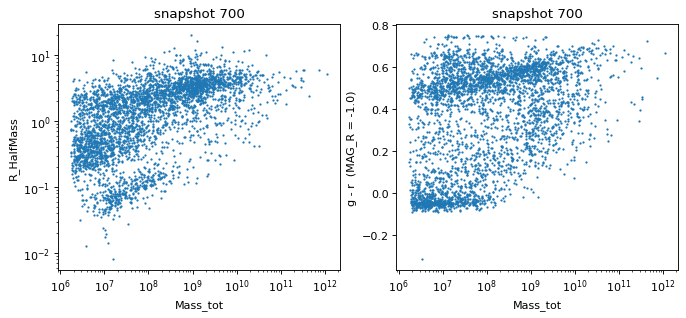

In [ ]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.loglog(cat['Mass_tot'], cat['R_HalfMass'], '.', ms=2)
ax1.set(xlabel='Mass_tot', ylabel='R_HalfMass', title=f'snapshot {SNAP}')

g_r = cat['ABmag_g'][:, 0] - cat['ABmag_r'][:, 0]
ax2.semilogx(cat['Mass_tot'], g_r, '.', ms=2)
ax2.set(xlabel='Mass_tot', ylabel=f"g - r  (MAG_R = {info['MAG_R'][0]})", title=f'snapshot {SNAP}')
plt.show()

## 8. A pandas table (needs pandas)

pandas needs 1-D columns, so each vector is split into one column per position (`SFR_0`, `SFR_1`, …):

In [ ]:
import pandas as pd

def to_dataframe(cat):
    columns = {}
    for name in cat.dtype.names:
        values = cat[name]
        if values.ndim == 1:
            columns[name] = values
        else:
            for k in range(values.shape[1]):
                columns[f'{name}_{k}'] = values[:, k]
    return pd.DataFrame(columns)

df = to_dataframe(cat)
df[['ID', 'Mass_tot', 'R_HalfMass', 'SFR_8']].sort_values('Mass_tot', ascending=False).head()

,ID,Mass_tot,R_HalfMass,SFR_8
0,1,1.142492e+12,5.131093,2.585631
2039,2040,7.415953e+11,5.935519,3.893374
2038,2039,4.413356e+11,2.376285,0.329506
2,3,3.443506e+11,5.903097,3.094408
1,2,3.287410e+11,4.067952,15.936181


## 9. Snapshot information (`snapinf_NNNN.txt`) and `error.txt`

Every snapshot in a download comes with a small text file of snapshot metadata.

### 9-(1) The file

Each line is `key = value`, and each value is written in JSON:

In [ ]:
SNAP = 700
path = DATA_DIR / f'snapinf_{SNAP:04d}.txt'
print(path.read_text())

CONF_R = [1.0, 3.0]
GAS_R = [1.0, 2.0, 3.0]
GRAV_R = [5.0]
MAG_R = [-1.0, 0.1, 1.0]
Flux_List = ["NUV", "u", "g", "r", "i", "z"]
SFR_R = [-1.0, 0.1, 1.0, -1.0, 0.1, 1.0, -1.0, 0.1, 1.0, -1.0, 0.1, 1.0, -1.0, 0.1, 1.0]
SFR_T = [0.01, 0.01, 0.01, 0.05, 0.05, 0.05, 0.1, 0.1, 0.1, 0.5, 0.5, 0.5, 1.0, 1.0, 1.0]
aexp = [0.592947107301629]



`read_snapinfo` returns a dict:

In [ ]:
info = nr.read_snapinfo(path)
for key, value in info.items():
    print(f'{key:10s} {type(value).__name__:5s} {value}')

CONF_R     list  [1.0, 3.0]
GAS_R      list  [1.0, 2.0, 3.0]
GRAV_R     list  [5.0]
MAG_R      list  [-1.0, 0.1, 1.0]
Flux_List  list  ['NUV', 'u', 'g', 'r', 'i', 'z']
SFR_R      list  [-1.0, 0.1, 1.0, -1.0, 0.1, 1.0, -1.0, 0.1, 1.0, -1.0, 0.1, 1.0, -1.0, 0.1, 1.0]
SFR_T      list  [0.01, 0.01, 0.01, 0.05, 0.05, 0.05, 0.1, 0.1, 0.1, 0.5, 0.5, 0.5, 1.0, 1.0, 1.0]
aexp       list  [0.592947107301629]


| Key | Contents |
|---|---|
| `aexp` | Scale factor of the snapshot, as a one-element list |
| `Flux_List` | Photometric bands: the `<band>` in `ABmag_<band>` |
| `MAG_R` | One value per position of `ABmag_<band>` |
| `GAS_R` | One value per position of `GasMass_<region>_<phase>` |
| `CONF_R` | One value per position of `ConFrac_M` and `ConFrac_N` |
| `GRAV_R` | The value used for `GravPressure` |
| `SFR_R`, `SFR_T` | One pair per position of `SFR` |

### 9-(2) Redshift

In [ ]:
aexp = info['aexp'][0]
print(f'aexp = {aexp:.5f}   z = {1 / aexp - 1:.4f}')

aexp = 0.59295   z = 0.6865


### 9-(3) All snapshots in a download

In [ ]:
print(' snap     aexp       z')
for p in sorted(DATA_DIR.glob('snapinf_*.txt')):
    a = nr.read_snapinfo(p)['aexp'][0]
    print(f'{int(p.stem[-4:]):5d} {a:8.5f} {1 / a - 1:7.4f}')

 snap     aexp       z
  700  0.59295  0.6865
  702  0.59386  0.6839
  704  0.59478  0.6813
  706  0.59570  0.6787
  708  0.59661  0.6761
  710  0.59752  0.6736
  712  0.59843  0.6710
  714  0.59934  0.6685
  716  0.60026  0.6659
  718  0.60118  0.6634
  720  0.60209  0.6609
  722  0.60301  0.6584
  724  0.60392  0.6559
  726  0.60483  0.6534
  728  0.60575  0.6509
  730  0.60666  0.6484
  732  0.60758  0.6459
  734  0.60849  0.6434
  736  0.60941  0.6409
  738  0.61031  0.6385
  740  0.61123  0.6360
  742  0.61215  0.6336
  744  0.61306  0.6312
  746  0.61397  0.6287
  748  0.61489  0.6263
  750  0.61581  0.6239


### 9-(4) Without `ndps_reader`

The format is simple enough to read with the standard library alone:

In [ ]:
import json

info2 = {}
for line in path.read_text().splitlines():
    key, _, value = line.partition(' = ')
    info2[key] = json.loads(value)
print(info2['aexp'], info2['Flux_List'])

[0.592947107301629] ['NUV', 'u', 'g', 'r', 'i', 'z']


### 9-(5) `error.txt`

`error.txt` appears only when some requested snapshots could not be produced. It has one line per missing snapshot, and every other file in the download is complete. In this example the simulation only has even-numbered snapshots in this range, so the odd ones are listed.

In [ ]:
import re

error_file = DATA_DIR / 'error.txt'
if error_file.exists():
    text = error_file.read_text()
    print(text.splitlines()[0])
    missing = [int(s) for s in re.findall(r'snapshot (\d+) is not available', text)]
    print(len(missing), 'missing snapshots:', missing)
else:
    print('No error.txt: every requested snapshot is included.')

Requested snapshot 701 is not available. (simulation=NewCluster, horg=g, file=snap_0701.hdf5)
25 missing snapshots: [701, 703, 705, 707, 709, 711, 713, 715, 717, 719, 721, 723, 725, 727, 729, 731, 733, 735, 737, 739, 741, 743, 745, 747, 749]


## Notes

- `nr.read(path)` works for every file in a download: it picks the reader from the file name.
- Pickle files are opened with a restricted loader that only rebuilds NumPy arrays, so a tampered file cannot run code. If you trust a file that it refuses, pass `trusted=True`.
- Pickles written with NumPy 2 also load on NumPy 1.x.